# Bregman proximal point minimization
Work in a real finite-dimensional Euclidean space. The functions $f,h$ are closed, proper, convex and differentiable as specified in the input, all stated evaluations and updates exist, $\alpha>0$, $R\ge0$, and $N\ge1$ is an integer. Let $x_\star$ minimize $f$ and assume $D_h(x_\star,x_0)\le R$.
$$D_h(u,v)=h(u)-h(v)-\langle\nabla h(v),u-v\rangle.$$
$$x_{k+1}\in\arg\min_x\{\alpha f(x)+D_h(x,x_k)\},\qquad k=0,\ldots,N-1.$$
The optimality relation used by the setup is
$$\nabla h(x_{k+1})=\nabla h(x_k)-\alpha\nabla f(x_{k+1}).$$
The performance metric is $f(x_N)-f(x_\star)$, with supplied conjecture $R/(\alpha N)$. Convex interpolation gives a relaxation valid for the differentiable class; the numerical results alone are not an arbitrary-horizon proof.

## Proof Statement

### Theorem
Let $f,h$ be closed, proper, convex and differentiable as specified, on a real finite-dimensional Euclidean space. Let $x_{\star}$ minimize $f$, let $\alpha>0$, $R\ge0$, and assume $D_h(x_{\star},x_{0})\le R$. Suppose every update $x_{k+1}\in\arg\min_x\{\alpha f(x)+D_h(x,x_{k})\}$ and stated evaluation exists. Then for every integer $N\ge1$, define
$$V_{k}=\frac{D_h(x_{\star},x_{k})-D_h(x_{\star},x_{0})}{\alpha N}+\frac{k}{N}\bigl(f(x_{k})-f(x_{\star})\bigr),\qquad 0\le k\le N.$$
Then $V_{0}=0$ and $V_{k+1}\le V_{k}$. In particular,
$$0\le f(x_{N})-f(x_{\star})\le\frac{R}{\alpha N}.$$
The formula applies at both endpoints and for $N=1$ and $R=0$. An equivalent conventional potential is $\Phi_{k}=\alpha k(f(x_{k})-f(x_{\star}))+D_h(x_{\star},x_{k})$; it is nonincreasing and $\Phi_{0}\le R$.

### Proof outline
Use the explicit certificate
$$V_{k}=\frac{D_h(x_{\star},x_{k})-D_h(x_{\star},x_{0})}{\alpha N}+\frac{k}{N}(f(x_{k})-f(x_{\star})).$$
For $q=f,h$, set
$$r^q_{i,j}=q(x_{j})-q(x_{i})+\langle\nabla q(x_{j}),x_{i}-x_{j}\rangle\le0.$$
The exact proximal optimality equation is $\nabla h(x_{k+1})=\nabla h(x_{k})-\alpha\nabla f(x_{k+1})$. Substitution yields, for $0\le k<N$,
$$V_{k+1}-V_{k}=\frac{r^f_{\star,k+1}}{N}+\frac{k}{N}r^f_{k,k+1}+\frac{k+1}{\alpha N}r^h_{k+1,k}+\frac{k}{\alpha N}r^h_{k,k+1}\le0.$$
Every multiplier is nonnegative because $k\ge0$, $N\ge1$, and $\alpha>0$. At the first step the two factors $k$ vanish, so the same statement has a separately verified base case. Since $V_{0}=0$, telescoping gives $V_{N}\le0$.
Finally,
$$f(x_{N})-f(x_{\star})-\frac{R}{\alpha N}=V_{N}+\frac{D_h(x_{\star},x_{0})-R}{\alpha N}+\frac{r^h_{\star,N}}{\alpha N}\le0.$$
This uses exactly the given radius $R$. Convexity and minimality of $x_{\star}$ give the lower bound. The executable symbolic checks below verify these identities over symbolic parameters and indices, not only the numerical discovery horizons.

In [1]:
from pathlib import Path
import sys
notebook_dir = Path.cwd().resolve()
REPO_ROOT = notebook_dir / "supplementary" / "approved"
sys.path[:0] = [str(REPO_ROOT), str(notebook_dir / "supplementary" / "helpers"), str(notebook_dir)]


In [2]:
from numbers import Number
from typing import cast
import runtime
import json
import pepflow as pf
import matplotlib.pyplot as plt
assert runtime.APPROVED == REPO_ROOT

## Functions, parameters, and algorithm setup
Both functions use convex interpolation; each proximal step encodes the exact optimality equation.

In [3]:
alpha = pf.Parameter("alpha")
R = pf.Parameter("R")
f = pf.ConvexFunction(is_basis=True, tags=["f"])
h = pf.ConvexFunction(is_basis=True, tags=["h"])


In [4]:
def make_ctx_bppm(ctx_name: str, N, **kwargs) -> pf.PEPContext:
    ctx = pf.PEPContext(ctx_name).set_as_current()
    x = pf.Vector(is_basis=True, tags=["x_0"])
    f.set_stationary_point("x_star")
    f(x)
    h(ctx["x_star"])
    h.grad(ctx["x_star"])
    for k in range(N):
        x = f.bregman_prox(x, cast(Number, alpha), h, tag=f"x_{k + 1}")
    return ctx


def get_pep_setup(N, params):
    ctx = make_ctx_bppm(f"ctx_{N}", N)
    pb = pf.PEPBuilder(ctx)
    x0, xs = ctx["x_0"], ctx["x_star"]
    divergence = h(xs) - h(x0) - h.grad(x0) * (xs - x0)
    pb.add_initial_constraint(divergence.le(R, name="initial_condition"))
    pb.set_performance_metric(f(ctx[f"x_{N}"]) - f(xs))
    return ctx, pb, f



## Numerical evidence
CLARABEL defaults, with $\alpha=R=1$. The saved sweep was generated once from the setup above.

N=1: PEP=1.0000000006, conjecture=1.0000000000, status=optimal
N=2: PEP=0.4999999958, conjecture=0.5000000000, status=optimal
N=3: PEP=0.3333333333, conjecture=0.3333333333, status=optimal
N=4: PEP=0.2499999995, conjecture=0.2500000000, status=optimal
N=5: PEP=0.1999999999, conjecture=0.2000000000, status=optimal
N=6: PEP=0.1666666661, conjecture=0.1666666667, status=optimal
N=7: PEP=0.1428571412, conjecture=0.1428571429, status=optimal
Maximum absolute error: 4.241049955666654e-09


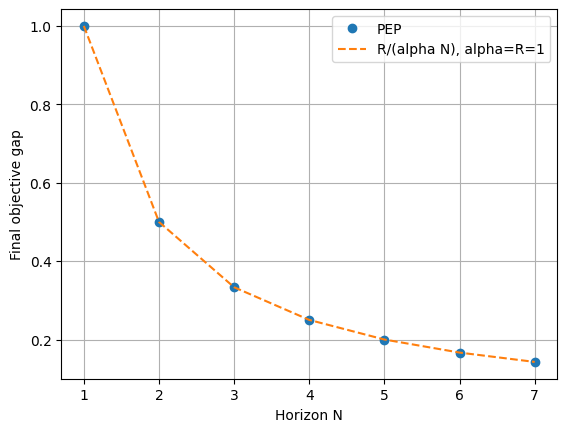

In [5]:
results = json.loads((notebook_dir / "state/bppm_b1.json").read_text())["sweep_results"]
for row in results:
    print(f"N={row['N']}: PEP={row['opt_value']:.10f}, conjecture={row['conjecture']:.10f}, status={row['status']}")
print("Maximum absolute error:", max(row["absolute_error"] for row in results))
ns = [row["N"] for row in results]
plt.plot(ns, [row["opt_value"] for row in results], "o", label="PEP")
plt.plot(ns, [1/n for n in ns], "--", label="R/(alpha N), alpha=R=1")
plt.xlabel("Horizon N")
plt.ylabel("Final objective gap")
plt.legend()
plt.grid(True)
plt.show()

The numerical values match the supplied conjecture to better than $10^{-5}$. Initial certificate horizon: $N=4$. The certificate, Lyapunov construction, and exact identities remain to be established.

## Dense and relaxed proof solves
The dense sample and selected relaxed sample each come from a single primal solve. CLARABEL defaults were used. The saved data include both function families and every initial multiplier. The code below makes the solve/capture and complete numerical verification reproducible; notebook execution revalidates the saved coherent sample without replacing it.

In [6]:
import hashlib
import json
import uuid
from pathlib import Path

import cvxpy as cp
import numpy as np
import pepflow as pf


def max_abs(values):
    return float(np.max(np.abs(np.asarray(values, dtype=float)), initial=0.0))


def entries_of(ctx, pb):
    entries = [(c, 'initial', None, None) for c in pb.init_conditions]
    for owner in ctx.func_to_triplets:
        groups = ctx.get_constraint_data(owner)
        entries.extend((c, 'interpolation', str(owner), str(group))
                       for group, constraints in groups.sc_dict.items() for c in constraints)
        assert not groups.psd_dict
    assert not ctx.oper_to_duplets
    assert len({c.name for c, *_ in entries}) == len(entries)
    return entries


def solve_capture(N, params, relaxed, root):
    source_paths = [root / 'bppm_setup.py', root / 'supplementary/b2_core.py']
    allowed = json.loads((root / 'supplementary/approved/allowlist.json').read_text())
    source_paths += [Path(p) for p in allowed['exact_read_files'] if Path(p).parent == root / 'supplementary/approved/pepflow']
    hashes = {str(p.relative_to(root)).replace('\\', '/'): hashlib.sha256(p.read_bytes()).hexdigest() for p in source_paths}
    ctx, pb, obj = get_pep_setup(N, params)
    pb.set_relaxed_constraints(relaxed)
    entries = entries_of(ctx, pb)
    constraints = [c for c, *_ in entries if c.name not in relaxed]
    solver = pf.CVXPrimalSolver(perf_metric=pb.performance_metric,
                               constraints=constraints, context=ctx)
    problem = solver.build_problem(resolve_parameters=params)
    options = {'solver': 'CLARABEL'}
    try:
        value = problem.solve(**options)
    except cp.error.SolverError:
        options = {'solver': 'SCS', 'eps': 1e-7, 'max_iters': 200000}
        value = problem.solve(**options)
    result = pf.PEPResult(opt_value=float(value), dual_var_manager=solver.dual_var_manager,
                          pep_type=pf.PEPType.PRIMAL, solver_status=problem.status, context=ctx)
    assert problem.status == 'optimal'
    S = result.get_gram_dual_matrix()
    meta, duals = {}, {}
    for c, origin, owner, group in entries:
        assert isinstance(c, pf.ScalarConstraint)
        dropped = c.name in relaxed
        d = result.get_dual_value(c.name)
        assert dropped or d is not None
        if d is not None:
            assert np.isfinite(d)
        meta[c.name] = dict(origin=origin, owner=owner, group=group, kind='scalar',
                            comparator=c.cmp.value, shape=[], relaxed=dropped)
        if dropped:
            duals[c.name] = None
        else:
            assert d is not None
            duals[c.name] = float(d)
    data = dict(N=N, N_verify=N, params_json=json.dumps(params), opt_value=float(value),
                tau_sol=duals['initial_condition'], tau_name='initial_condition',
                relaxed_constraints=relaxed, S_matrix=np.asarray(S.matrix, dtype=float).tolist(),
                S_row_names=list(S.row_names), S_col_names=list(S.col_names),
                basis_vectors=[str(v) for v in ctx.basis_vectors()],
                basis_scalars=[str(v) for v in ctx.basis_scalars()],
                named_dual_values=duals, constraint_metadata=meta,
                certificate_provenance=dict(solve_id=str(uuid.uuid4()), pep_type='primal',
                    solver_status=problem.status, source_hashes=hashes,
                    solver=dict(api='CVXPrimalSolver.build_problem + cvxpy.Problem.solve',
                                cvxpy_version=cp.__version__, effective_name=problem.solver_stats.solver_name, settings=options)),
                normalization=dict(tau_name='initial_condition', initial_condition='D_h(x_star,x_0)<=R',
                    performance_metric='f(x_N)-f(x_star)', bound_value=float(value), bound_formula='R/(alpha*N)'))
    print('N, bound, solver:', N, value, problem.solver_stats.solver_name)
    for owner in ('f', 'h'):
        print(owner, [(name, round(d, 7)) for name, d in duals.items() if name.startswith(owner + ':') and d is not None and abs(d) > 1e-6])
    print('S max, eigenvalues:', max_abs(S.matrix), np.linalg.eigvalsh(S.matrix))
    return ctx, pb, result, data


def candidate_weights(N, a):
    weights = {'initial_condition': 1/(a*N), f'h:x_star,x_{N}': 1/(a*N)}
    for k in range(1, N+1):
        weights[f'f:x_star,x_{k}'] = 1/N
        weights[f'h:x_{k},x_{k-1}'] = k/(a*N)
        if k >= 2:
            weights[f'f:x_{k-1},x_{k}'] = (k-1)/N
            weights[f'h:x_{k-1},x_{k}'] = (k-1)/(a*N)
    return weights


def verify_certificate(ctx, pb, data, dense_value):
    from pepflow.utils import Comparator
    pm = pf.ExpressionManager(ctx, resolve_parameters=json.loads(data['params_json']))
    basis = ctx.basis_vectors()
    S = np.asarray(data['S_matrix'], dtype=float)
    eig, Q = np.linalg.eigh(S)
    D, E = np.diag(eig), Q.T
    ell = [sum((float(v)*b for v, b in zip(row, basis)), pf.Vector.zero()) for row in E]
    S_numeric = sum((float(eig[i])*ell[i]*ell[i] for i in range(len(eig))), pf.Scalar.zero())
    weighted = pf.Scalar.zero()
    min_dual = 0.0
    entries = entries_of(ctx, pb)
    assert {c.name for c, *_ in entries} == set(data['named_dual_values']) == set(data['constraint_metadata'])
    for c, *_ in entries:
        meta = data['constraint_metadata'][c.name]
        value = data['named_dual_values'][c.name]
        if meta['relaxed']:
            assert value is None
            continue
        assert value is not None
        residual = c.lhs-c.rhs
        if c.cmp in (Comparator.GE, Comparator.SEQ):
            residual = -residual
        weighted += float(value)*residual
        if c.cmp != Comparator.EQ:
            min_dual = min(min_dual, value)
    checked = pm.eval_scalar(pb.performance_metric-data['opt_value']-weighted+S_numeric)
    residuals = dict(identity_gram_max_abs=max_abs(checked.inner_prod_coords),
        identity_func_max_abs=max_abs(checked.func_coords), identity_offset_abs=max_abs(checked.offset),
        S_reconstruction_max_abs=max_abs(E.T@D@E-S), dense_relaxed_gap=abs(dense_value-data['opt_value']),
        minimum_scalar_inequality_dual=min_dual, minimum_S_eigenvalue=float(eig.min()),
        minimum_matrix_inequality_eigenvalue=0.0)
    tolerances = dict(identity_atol=1e-5,identity_rtol=0.0,reconstruction_atol=1e-4,
        reconstruction_rtol=1e-5,dual_tol=1e-6,psd_tol=1e-6,dense_opt_atol=1e-5)
    assert all(residuals[k] <= 1e-5 for k in ('identity_gram_max_abs','identity_func_max_abs','identity_offset_abs'))
    assert np.allclose(E.T@D@E,S,atol=1e-4,rtol=1e-5)
    assert np.allclose(S,S.T,atol=1e-6,rtol=0)
    assert np.all(np.isfinite(S))
    assert min_dual >= -1e-6 and eig.min() >= -1e-6
    assert residuals['dense_relaxed_gap'] < 1e-5
    assert data['certificate_provenance']['solver_status'] == 'optimal'
    data['numerical_decomposition'] = dict(method='direct',factorization='eigendecomposition',D=D.tolist(),ell_coords=E.tolist(),basis_labels=[str(b) for b in basis])
    data['numerical_checks'] = dict(tolerances=tolerances,residuals=residuals,passed=True)
    data['numerical_certificate_verified'] = True
    print('Full coordinate certificate checks:', residuals)
    return checked


In [7]:
dense = json.loads((notebook_dir / "state/bppm_dense.json").read_text())
b2 = json.loads((notebook_dir / "state/bppm_b2.json").read_text())
print("Dense bound:", dense["opt_value"])
print("Basis vectors:", dense["basis_vectors"])
for owner in ("f", "h"):
    print(owner, "dense active:", [(n, round(v,7)) for n,v in dense["named_dual_values"].items() if n.startswith(owner+":") and v is not None and abs(v)>1e-6])
print("Dense S maximum:", max_abs(dense["S_matrix"]))
N = b2["N_verify"]
params = json.loads(b2["params_json"])
candidate = candidate_weights(N, params["alpha"])
relaxed = [n for n in dense["constraint_metadata"] if n not in candidate]
assert relaxed == b2["relaxed_constraints"]
print("Dropped constraints:", len(relaxed))
print("Selected bound:", b2["opt_value"], "preserved gap:", abs(dense["opt_value"]-b2["opt_value"]))
for owner in ("f", "h"):
    print(owner, "selected active:", [(n,round(v,7)) for n,v in b2["named_dual_values"].items() if n.startswith(owner+":") and v is not None and abs(v)>1e-6])

Dense bound: 0.2499999995235287
Basis vectors: ['x_0', 'x_star', 'grad_f(x_0)', 'grad_h(x_star)', 'x_1', 'grad_f(x_1)', 'grad_h(x_0)', 'x_2', 'grad_f(x_2)', 'x_3', 'grad_f(x_3)', 'x_4', 'grad_f(x_4)']
f dense active: [('f:x_star,x_1', 0.25), ('f:x_star,x_2', 0.25), ('f:x_star,x_3', 0.25), ('f:x_star,x_4', 0.25), ('f:x_1,x_2', 0.13709), ('f:x_1,x_3', 0.0731308), ('f:x_1,x_4', 0.0397792), ('f:x_2,x_3', 0.2545141), ('f:x_2,x_4', 0.1325759), ('f:x_3,x_4', 0.5776448)]
h dense active: [('h:x_star,x_4', 0.25), ('h:x_1,x_0', 0.25), ('h:x_1,x_2', 0.0639592), ('h:x_1,x_3', 0.0333515), ('h:x_1,x_4', 0.0397792), ('h:x_2,x_1', 0.38709), ('h:x_2,x_3', 0.1219381), ('h:x_2,x_4', 0.1325759), ('h:x_3,x_2', 0.5776448), ('h:x_3,x_4', 0.5776448), ('h:x_4,x_3', 1.0)]
Dense S maximum: 2.8944308375966715e-10
Dropped constraints: 45
Selected bound: 0.24999999998930528 preserved gap: 4.657765839688466e-10
f selected active: [('f:x_star,x_1', 0.25), ('f:x_star,x_2', 0.25), ('f:x_star,x_3', 0.25), ('f:x_star,x_4'

## Lambda and S verification
Convex interpolation residuals are $r^q_{i,j}=q(x_j)-q(x_i)+\langle\nabla q(x_j),x_i-x_j\rangle\le0$.
The initial formula search used the dense support and then the consecutive-pair relaxation. For $1\le k\le N$, the candidate $f$ weights are $\lambda^f_{\star,k}=1/N$ and $\lambda^f_{k-1,k}=(k-1)/N$. The latter vanishes for $k=1$.
The candidate $h$ weights are $\lambda^h_{k,k-1}=k/(\alpha N)$ and $\lambda^h_{k-1,k}=(k-1)/(\alpha N)$, together with $\lambda^h_{\star,N}=1/(\alpha N)$ and initial multiplier $1/(\alpha N)$. All other multipliers vanish. The candidate Gram remainder is $S=0$.
These are **numerically supported candidates**. No all-horizon analytic full-PEP proof is claimed here. The actual small numerical $S$ is retained exactly as saved and reconstructed through its eigendecomposition.

In [8]:
for owner in ("f", "h"):
    labels = ["x_star"] + [f"x_{k}" for k in range(N+1)]
    matrix = np.array([[candidate.get(f"{owner}:{i},{j}",0.0) for j in labels] for i in labels])
    print(owner, "candidate multiplier matrix")
    pf.pprint_labeled_matrix(pf.MatrixWithNames(matrix,labels,labels))
error = max(abs(v-candidate[name]) for name,v in b2["named_dual_values"].items() if v is not None)
assert error < 1e-4
print("Candidate multiplier error:",error)
print("Candidate S=0 error:",max_abs(b2["S_matrix"]))
assert max_abs(b2["S_matrix"]) < 1e-4
print("Candidate S matrix:")
pf.pprint_labeled_matrix(pf.MatrixWithNames(np.zeros_like(b2["S_matrix"]),b2["S_row_names"],b2["S_col_names"]))

f candidate multiplier matrix


<IPython.core.display.Math object>

h candidate multiplier matrix


<IPython.core.display.Math object>

Candidate multiplier error: 3.3287683720573114e-10
Candidate S=0 error: 1.9119710294695356e-10
Candidate S matrix:


<IPython.core.display.Math object>

For each scalar constraint use its actual normalized residual $r\le0$. With the selected numerical multipliers and its original $S$, check
$$\mathrm{metric}-\mathrm{bound}-\sum_c d_c r_c+\sum_{i,j}S_{ij}\langle b_i,b_j\rangle=0.$$
The executable verifier above checks every scalar coordinate, the sign of every active multiplier, PSD of $S$, its factor reconstruction, and preservation of the dense optimum. No active small multiplier or remainder is silently removed.

In [9]:
ctx, pb, obj = get_pep_setup(N, params)
pb.set_relaxed_constraints(b2["relaxed_constraints"])
assert [str(v) for v in ctx.basis_vectors()] == b2["basis_vectors"]
assert [str(v) for v in ctx.basis_scalars()] == b2["basis_scalars"]
for relative, expected in b2["certificate_provenance"]["source_hashes"].items():
    assert hashlib.sha256((notebook_dir/relative).read_bytes()).hexdigest() == expected
checked = verify_certificate(ctx, pb, b2, dense["opt_value"])
print("Numerical S decomposition: full eigenbasis, all eigenvalues retained")
print("Diagonal D:",np.diag(np.asarray(b2["numerical_decomposition"]["D"])))
print("Gram identity residual:")
pf.pprint_labeled_matrix(pf.MatrixWithNames(np.asarray(checked.inner_prod_coords,dtype=float),b2["basis_vectors"],b2["basis_vectors"]))
print("Function coordinates:",checked.func_coords)
print("Constant:",checked.offset)
print("Search record:",b2["closed_form_search"])
print("Numerical certificate verified:",b2["numerical_certificate_verified"])
print("Analytic full-PEP verified:",b2["analytic_full_pep_verified"])
print("Lyapunov proof verified:",b2["lyapunov_proof_verified"])
print("Actual selected numerical S:")
pf.pprint_labeled_matrix(pf.MatrixWithNames(np.asarray(b2["S_matrix"]),b2["S_row_names"],b2["S_col_names"]))

Full coordinate certificate checks: {'identity_gram_max_abs': 1.9119710294695349e-10, 'identity_func_max_abs': 8.855547406483311e-10, 'identity_offset_abs': 2.0461143890315725e-10, 'S_reconstruction_max_abs': 4.1359030627651384e-25, 'dense_relaxed_gap': 4.657765839688466e-10, 'minimum_scalar_inequality_dual': 0.0, 'minimum_S_eigenvalue': 9.192492405114347e-11, 'minimum_matrix_inequality_eigenvalue': 0.0}
Numerical S decomposition: full eigenbasis, all eigenvalues retained
Diagonal D: [9.19249241e-11 1.59475678e-10 1.74155200e-10 1.85651347e-10
 1.91197060e-10 1.91197086e-10 1.91197087e-10 1.91197087e-10
 1.91197114e-10 1.96742799e-10 2.08238939e-10 2.22918465e-10
 2.90469253e-10]
Gram identity residual:


<IPython.core.display.Math object>

Function coordinates: [ 8.85554741e-10  0.00000000e+00 -1.66533454e-16 -1.11022302e-16
 -5.55111512e-17  2.21388907e-10 -2.21388574e-10  0.00000000e+00
 -2.21388685e-10 -2.22044605e-16 -4.42777370e-10 -2.21388463e-10]
Constant: 2.0461143890315725e-10
Search record: {'completed': True, 'references_reviewed': ['own approved input and generic function/solver API; target-specific references prohibited'], 'attempts': ['Dense multipliers suggest star-to-iterate f terms and forward pairs; selected consecutive-only f/h relaxation.', 'Rational inspection yields f star weights 1/N, consecutive f weights (k-1)/N; h forward weights k/(alpha*N), reverse weights (k-1)/(alpha*N), terminal weight 1/(alpha*N).', 'Compared every active numerical multiplier and S=0 to the selected sample.'], 'candidate_lambda_max_error': 3.3287683720573114e-10, 'candidate_S_max_error': 1.9119710294695356e-10, 'unresolved_components': ['All-horizon analytic identity and parameter-domain proof are deferred; candidates veri

<IPython.core.display.Math object>

### Additional coherent certificate for rank confirmation
B3 requested a distinct horizon. B2 acquired the $N=6$ dense and consecutive-pair samples with the same solver settings and formula recipe. This cell independently checks the supplementary certificate; the selected $N=4$ state remains unchanged.

In [10]:
confirmation = json.loads((notebook_dir/"supplementary/bppm_N6_b2.json").read_text())
dense6 = json.loads((notebook_dir/"supplementary/bppm_N6_dense.json").read_text())
params6 = json.loads(confirmation["params_json"])
ctx6, pb6, obj6 = get_pep_setup(confirmation["N_verify"], params6)
pb6.set_relaxed_constraints(confirmation["relaxed_constraints"])
for relative, expected in confirmation["certificate_provenance"]["source_hashes"].items():
    assert hashlib.sha256((notebook_dir/relative).read_bytes()).hexdigest() == expected
checked6 = verify_certificate(ctx6, pb6, confirmation, dense6["opt_value"])
print("Additional horizon:",confirmation["N_verify"], "dense bound:",dense6["opt_value"], "selected bound:",confirmation["opt_value"])
print("Candidate checks:",confirmation["closed_form_search"]["candidate_lambda_max_error"],confirmation["closed_form_search"]["candidate_S_max_error"])
ctx.set_as_current()

Full coordinate certificate checks: {'identity_gram_max_abs': 5.104187512907829e-10, 'identity_func_max_abs': 3.5669680542582682e-09, 'identity_offset_abs': 7.105981914001802e-10, 'S_reconstruction_max_abs': 1.34416849539867e-24, 'dense_relaxed_gap': 4.145392085153077e-10, 'minimum_scalar_inequality_dual': 0.0, 'minimum_S_eigenvalue': 2.9284622690354593e-10, 'minimum_matrix_inequality_eigenvalue': 0.0}
Additional horizon: 6 dense bound: 0.16666666606928843 selected bound: 0.16666666648382764
Candidate checks: 8.20438328386075e-10 5.104187512907835e-10


## Lyapunov partial sums and rank profile
Let $r^q_{i,j}$ denote the convex interpolation residual defined above. Assign both directed consecutive $h$ terms and the associated $f$ terms to their newest iterate. With the **saved numerical** coefficients $d$, define $V_0=0$ and
$$V_k-V_{k-1}=d^f_{\star,k}r^f_{\star,k}+d^f_{k-1,k}r^f_{k-1,k}+d^h_{k,k-1}r^h_{k,k-1}+d^h_{k-1,k}r^h_{k-1,k}.$$
The terms with zero support at $k=1$ are absent. All assigned residuals are nonpositive, so this convention makes $V_k$ nonincreasing. Retain the one terminal residual $d^h_{\star,N}r^h_{\star,N}$ and the entire small numerical PSD matrix $S$ as boundary contributions; no certificate term is discarded.
Rebuild and recheck each sample below, then compute its partial sums, ranks, and all-coordinate coverage. Rank 4 is observed across horizons 4 and 6 after excluding $V_0$ and $V_N$, with at least three retained indices per horizon. This is finite-sample structure, not an analytic theorem.

In [11]:
import sympy as sp
rank_samples=[]
for sample_file in ("supplementary/bppm_N6_b2.json", "state/bppm_b2.json"):
    certificate=json.loads((notebook_dir/sample_file).read_text())
    N_int=certificate['N_verify']
    params_sp={k:sp.S(v) for k,v in json.loads(certificate['params_json']).items()}
    ctx,pb,obj=get_pep_setup(N_int,params_sp)
    pb.set_relaxed_constraints(certificate['relaxed_constraints'])
    ctx.set_as_current()
    print('Certificate horizon:',N_int)
    import hashlib
    import json
    from pathlib import Path
    import numpy as np
    import sympy as sp
    import pepflow as pf
    from pepflow.constraint import ScalarConstraint
    from pepflow.operator import LinearOperatorTranspose
    from pepflow.pep_result import MatrixWithNames
    from pepflow.utils import name_to_vector_tuple

    certificate_checked = False
    if not certificate.get("numerical_certificate_verified", False):
        raise ValueError("Recover or verify the complete numerical certificate in Block 2")
    if not certificate.get("closed_form_search", {}).get("completed", False):
        raise ValueError("Complete or recover Block 2's initial closed-form attempt")
    certificate_keys = (
        "N_verify", "params_json", "relaxed_constraints",
        "S_matrix", "S_row_names", "S_col_names", "basis_vectors", "basis_scalars",
        "opt_value", "tau_sol", "tau_name", "named_dual_values", "constraint_metadata",
        "normalization", "certificate_provenance", "numerical_checks",
        "numerical_decomposition",
    )
    payload = {key: certificate[key] for key in certificate_keys}
    digest = hashlib.sha256(json.dumps(
        payload, sort_keys=True, separators=(",", ":"), allow_nan=False
    ).encode("utf-8")).hexdigest()
    if digest != certificate["certificate_id"]:
        raise ValueError("Certificate components changed; recover one coherent certificate")
    provenance = certificate["certificate_provenance"]
    if provenance["pep_type"] != "primal":
        raise ValueError("Recover and verify the certificate's actual dual sign convention")
    for relative_path, expected_hash in provenance["source_hashes"].items():
        source_path = (notebook_dir / relative_path).resolve()
        if not source_path.is_relative_to(notebook_dir):
            raise ValueError("Certificate source path must stay in the selected repository")
        if hashlib.sha256(source_path.read_bytes()).hexdigest() != expected_hash:
            raise ValueError(f"Certificate source changed: {relative_path}")
    if not Path(pf.__file__).resolve().is_relative_to(notebook_dir):
        raise ValueError("The imported PEPFlow source is not the selected repository")
    if N_int != certificate["N_verify"]:
        raise ValueError("Certificate horizon differs from the rebuilt setup")
    saved_params = json.loads(certificate["params_json"])
    expected_params = {
        key: (sp.Rational(value) if isinstance(value, str) else
              sp.nsimplify(value, rational=True, tolerance=1e-9)
              if isinstance(value, float) else sp.S(value))
        for key, value in saved_params.items()
    }
    if params_sp != expected_params:
        raise ValueError("Certificate parameters differ from the rebuilt setup")
    if not certificate["numerical_checks"]["passed"]:
        raise ValueError("Block 2 numerical checks did not pass")
    tol = certificate["numerical_checks"]["tolerances"]

    records = [(c, "initial", None, None) for c in pb.init_conditions]
    owners = list(ctx.func_to_triplets) + [
        owner for owner in ctx.oper_to_duplets
        if not isinstance(owner, LinearOperatorTranspose)
    ]
    for owner in owners:
        data = ctx.get_constraint_data(owner)
        for group, family in data.sc_dict.items():
            records.extend((c, "interpolation", str(owner), str(group)) for c in family)
        records.extend((c, "interpolation", str(owner), str(group))
                       for group, c in data.psd_dict.items())
    constraints_by_name = {c.name: c for c, _, _, _ in records}
    if len(constraints_by_name) != len(records):
        raise ValueError("Constraint names must identify one unique contribution")
    saved_meta = certificate["constraint_metadata"]
    saved_duals = certificate["named_dual_values"]
    if set(constraints_by_name) != set(saved_meta) or set(saved_duals) != set(saved_meta):
        raise ValueError("The saved certificate does not cover the rebuilt constraints")
    relaxed = set(certificate["relaxed_constraints"])
    if set(pb.relaxed_constraints) != relaxed or not relaxed.issubset(constraints_by_name):
        raise ValueError("The selected relaxation differs from the saved certificate")
    if pb.ctx is not ctx:
        raise ValueError("The builder and expression context differ")
    basis = list(ctx.basis_vectors())
    basis_labels = [repr(v) for v in basis]
    scalar_labels = [repr(v) for v in ctx.basis_scalars()]
    if basis_labels != certificate["basis_vectors"] or scalar_labels != certificate["basis_scalars"]:
        raise ValueError("Certificate coordinate order differs from the rebuilt context")
    if certificate["S_row_names"] != basis_labels or certificate["S_col_names"] != basis_labels:
        raise ValueError("S labels do not match the rebuilt basis")
    S_array = np.asarray(certificate["S_matrix"], dtype=float)
    if S_array.shape != (len(basis), len(basis)) or not np.all(np.isfinite(S_array)):
        raise ValueError("Invalid S shape or entries")
    if not np.allclose(S_array, S_array.T, atol=tol["psd_tol"], rtol=0):
        raise ValueError("S is not numerically symmetric")
    if len(basis) and np.linalg.eigvalsh((S_array + S_array.T) / 2).min() < -tol["psd_tol"]:
        raise ValueError("S failed the recorded PSD tolerance")
    S_sol = MatrixWithNames(S_array, basis_labels, basis_labels)
    pm = pf.ExpressionManager(ctx, resolve_parameters=params_sp)
    S_scalar = sum((float(S_array[i, j]) * basis[i] * basis[j]
                    for i, j in np.ndindex(S_array.shape)), pf.Scalar.zero())

    weighted_terms = {}
    interpolation_terms = {}
    interpolation_pairs = {}
    extra_terms = {}
    extra_duals = {}
    for constraint, origin, owner, group in records:
        name = constraint.name
        kind = "scalar" if isinstance(constraint, ScalarConstraint) else "psd"
        residual = constraint.lhs - constraint.rhs
        shape = [] if kind == "scalar" else list(np.shape(residual))
        expected_meta = dict(origin=origin, owner=owner, group=group, kind=kind,
                             comparator=constraint.cmp.value, shape=shape,
                             relaxed=name in relaxed)
        if any(saved_meta[name].get(key) != value for key, value in expected_meta.items()):
            raise ValueError(f"Constraint metadata changed: {name}")
        value = saved_duals[name]
        if name in relaxed:
            if value is not None:
                raise ValueError(f"A relaxed constraint must have no retained multiplier: {name}")
            continue
        if value is None:
            raise ValueError(f"Missing unrelaxed dual: {name}")
        dual = np.asarray(value, dtype=float)
        if list(dual.shape) != shape or not np.all(np.isfinite(dual)):
            raise ValueError(f"Invalid saved dual: {name}")
        # Normalize inequalities to residual <= 0; primal equality duals keep their sign.
        if constraint.cmp.name in ("GE", "SEQ"):
            residual = -residual
        if kind == "scalar":
            if constraint.cmp.name != "EQ" and float(dual) < -tol["dual_tol"]:
                raise ValueError(f"Negative inequality multiplier: {name}")
            contribution = pf.Scalar.zero() + float(dual) * residual
        else:
            if constraint.cmp.name != "EQ" and not np.allclose(dual, dual.T, atol=tol["psd_tol"], rtol=0):
                raise ValueError(f"Nonsymmetric matrix dual: {name}")
            if constraint.cmp.name != "EQ" and dual.size and np.linalg.eigvalsh((dual + dual.T) / 2).min() < -tol["psd_tol"]:
                raise ValueError(f"Matrix dual is not PSD: {name}")
            contribution = sum((float(dual[i, j]) * residual[j, i]
                                for i, j in np.ndindex(dual.shape)), pf.Scalar.zero())
        weighted_terms[name] = contribution
        if origin == "interpolation" and kind == "scalar":
            interpolation_terms[name] = contribution
            try:
                interpolation_pairs[name] = name_to_vector_tuple(name)
            except (ValueError, IndexError):
                interpolation_pairs[name] = None  # Assign this term explicitly when grouping.
        elif name != certificate["tau_name"]:
            extra_terms[name] = contribution
            extra_duals[name] = value

    tau_name = certificate["tau_name"]
    if (tau_name not in weighted_terms or saved_meta[tau_name]["origin"] != "initial"
            or saved_meta[tau_name]["kind"] != "scalar" or tau_name in relaxed
            or certificate["normalization"]["tau_name"] != tau_name):
        raise ValueError("Missing or inconsistent bound normalization constraint")
    if not np.allclose(saved_duals[tau_name], certificate["tau_sol"], atol=tol["dual_tol"], rtol=0):
        raise ValueError("The saved normalization dual is inconsistent")
    if not np.isfinite(certificate["opt_value"]) or not np.allclose(
        certificate["normalization"]["bound_value"], certificate["opt_value"],
        atol=tol["identity_atol"], rtol=tol["identity_rtol"]
    ):
        raise ValueError("The saved bound/normalization is inconsistent")
    certificate_diff = (pb.performance_metric - float(certificate["opt_value"])
                        - sum(weighted_terms.values(), pf.Scalar.zero()) + S_scalar)
    evaluated_diff = pm.eval_scalar(certificate_diff)
    for label, coords in (
        ("Gram", evaluated_diff.inner_prod_coords),
        ("function", evaluated_diff.func_coords),
        ("offset", np.asarray(evaluated_diff.offset)),
    ):
        if not np.allclose(np.asarray(coords, dtype=float), 0,
                           atol=tol["identity_atol"], rtol=tol["identity_rtol"]):
            raise ValueError(f"Numerical certificate {label} identity failed")
    decomposition = certificate["numerical_decomposition"]
    D_saved = np.asarray(decomposition["D"], dtype=float)
    E_saved = np.asarray(decomposition["ell_coords"], dtype=float)
    if decomposition["basis_labels"] != basis_labels or E_saved.ndim != 2:
        raise ValueError("Numerical S decomposition basis differs")
    if E_saved.shape[1] != len(basis) or D_saved.shape != (E_saved.shape[0], E_saved.shape[0]):
        raise ValueError("Numerical S decomposition shape differs")
    if not np.all(np.isfinite(D_saved)) or not np.all(np.isfinite(E_saved)):
        raise ValueError("Numerical S decomposition contains nonfinite values")
    if not np.allclose(E_saved.T @ D_saved @ E_saved, S_array,
                       atol=tol["reconstruction_atol"], rtol=tol["reconstruction_rtol"]):
        raise ValueError("Numerical S decomposition does not reconstruct this certificate")
    certificate_checked = True
    print("Numerical certificate checked for this N and parameter sample.")

    # Retain the entire selected S as one terminal PSD block; no eigenvalue dropped.
    S_piece_terms = {'terminal_S': S_scalar}
    S_assignment = {'terminal_S': 'boundary'}

    # All residuals are normalized <=0, with nonnegative numerical multipliers.
    # Thus each increment is nonpositive; V_0=0 and V_k is nonincreasing.
    grouping_checked = False
    rank_tolerance = 1e-4
    rank_left, rank_right = 1, 1
    group_terms = {name: term for name, term in weighted_terms.items() if name != tau_name}
    term_assignment = {}
    for name in group_terms:
        owner, points = name.split(':')
        ri, ci = points.split(',')
        if owner == 'h' and ri == 'x_star':
            assert ci == f'x_{N_int}'
            term_assignment[name] = 'boundary'
        elif ri == 'x_star':
            term_assignment[name] = int(ci.split('_')[1])-1
        else:
            i, j = int(ri.split('_')[1]), int(ci.split('_')[1])
            assert abs(i-j) == 1
            term_assignment[name] = max(i,j)-1
    assert set(term_assignment) == set(group_terms)
    assert set(S_assignment) == set(S_piece_terms)
    lyap = [pf.Scalar.zero()]
    partial_sum = pf.Scalar.zero()
    for step in range(N_int):
        partial_sum += sum((group_terms[name] for name, target in term_assignment.items() if target == step), pf.Scalar.zero())
        partial_sum -= sum((S_piece_terms[name] for name, target in S_assignment.items() if target == step), pf.Scalar.zero())
        lyap.append(partial_sum)
    ranks, singular_values = [], []
    for k,Vk in enumerate(lyap):
        matrix = np.asarray(pm.eval_scalar(Vk).inner_prod_coords,dtype=float)
        singular = np.linalg.svd(matrix,compute_uv=False)
        rank = int(np.count_nonzero(singular > rank_tolerance))
        ranks.append(rank)
        singular_values.append(singular.tolist())
        print(f'rank V_{k}: {rank}')
        if k == 0:
            print()
    retained_ranks = ranks[rank_left:N_int+1-rank_right]
    print('Interior rank is constant at this N:',len(retained_ranks)>=3 and len(set(retained_ranks))==1,'boundary exclusions:',(rank_left,rank_right))
    rank_credible = all(not np.any((np.asarray(s)>rank_tolerance/10)&(np.asarray(s)<rank_tolerance*10)) for s in singular_values)
    assert rank_credible

    boundary_names = [name for name, step in term_assignment.items() if step == "boundary"]
    boundary_S = [name for name, step in S_assignment.items() if step == "boundary"]
    if sum(name in interpolation_terms for name in boundary_names) > 1 or len(boundary_S) > 1:
        raise ValueError("Revisit the permitted terminal interpolation/S leftovers")
    omitted = sum((group_terms[name] for name, step in term_assignment.items()
                   if step == "omitted"), pf.Scalar.zero())
    leftover = sum((group_terms[name] for name in boundary_names), pf.Scalar.zero())
    leftover -= sum((S_piece_terms[name] for name in boundary_S), pf.Scalar.zero())
    coverage_diff = (lyap[N_int] + leftover + omitted
                     - (sum(group_terms.values(), pf.Scalar.zero()) - S_scalar))
    piece_diff = sum(S_piece_terms.values(), pf.Scalar.zero()) - S_scalar
    for label, expression in (("coverage", coverage_diff), ("S pieces", piece_diff), ("omitted", omitted)):
        value = pm.eval_scalar(expression)
        for coords in (value.inner_prod_coords, value.func_coords, np.asarray(value.offset)):
            if not np.allclose(np.asarray(coords, dtype=float), 0,
                               atol=tol["identity_atol"], rtol=tol["identity_rtol"]):
                raise ValueError(f"Full-coordinate {label} check failed")
    # Every subtracted S piece must have the nonnegative numerical sign used here.
    for name, piece in S_piece_terms.items():
        value = pm.eval_scalar(piece)
        matrix = np.asarray(value.inner_prod_coords, dtype=float)
        if not np.allclose(value.func_coords, 0, atol=tol["identity_atol"], rtol=0) or not np.allclose(value.offset, 0, atol=tol["identity_atol"], rtol=0):
            raise ValueError(f"S piece has unexpected function/offset terms: {name}")
        if matrix.size and np.linalg.eigvalsh((matrix + matrix.T) / 2).min() < -tol["psd_tol"]:
            raise ValueError(f"S piece has the wrong numerical sign: {name}")
    # Step identities follow the chosen assignments; check them, including the initial terms.
    for k in range(N_int):
        assigned_steps = {-1, 0} if k == 0 else {k}
        increment = sum((group_terms[name] for name, step in term_assignment.items()
                         if step in assigned_steps), pf.Scalar.zero())
        increment -= sum((S_piece_terms[name] for name, step in S_assignment.items()
                          if step in assigned_steps), pf.Scalar.zero())
        value = pm.eval_scalar(lyap[k + 1] - lyap[k] - increment)
        for coords in (value.inner_prod_coords, value.func_coords, np.asarray(value.offset)):
            if not np.allclose(np.asarray(coords, dtype=float), 0,
                               atol=tol["identity_atol"], rtol=tol["identity_rtol"]):
                raise ValueError(f"Partial-sum increment identity failed at k={k}")
    grouping_checked = True
    M_final = pm.eval_scalar(lyap[N_int]).inner_prod_coords.astype(float)
    rank_final = int(np.linalg.matrix_rank(M_final, tol=rank_tolerance))
    print(f"lyap[{N_int}] rank:", rank_final)
    print("Coverage checked with all scalar components and explicit boundary leftovers.")

    rank_samples.append({'N':N_int,'certificate_id':certificate['certificate_id'],'recipe_id':'consecutive_residuals_terminal_h_and_S','rank_profile':ranks,'rank_convention':{'tolerance':rank_tolerance,'scaling':'absolute singular values, unscaled Gram coordinates','coordinate_order':'setup basis order'},'rank_credible':rank_credible,'certificate_checked':certificate_checked,'grouping_checked':grouping_checked,'singular_values':singular_values})


Certificate horizon: 6


C:\Users\Jack\Documents\GitHub\PEPFlow\examples_peppy\_evaluations\20260923T140754Z_paper5_pgm_sos_6x5_isolation1\bppm\r04\supplementary\approved\pepflow\pep_context.py:172: UserWarning:

The provided name was already used. The older PEPContext will be overwritten. PEPBuilders constructed with the older PEPContext should be remade.



Numerical certificate checked for this N and parameter sample.
rank V_0: 0

rank V_1: 4
rank V_2: 4
rank V_3: 4
rank V_4: 4
rank V_5: 4
rank V_6: 4
Interior rank is constant at this N: True boundary exclusions: (1, 1)
lyap[6] rank: 4
Coverage checked with all scalar components and explicit boundary leftovers.
Certificate horizon: 4


Numerical certificate checked for this N and parameter sample.
rank V_0: 0

rank V_1: 4
rank V_2: 4
rank V_3: 4
rank V_4: 4
Interior rank is constant at this N: True boundary exclusions: (1, 1)
lyap[4] rank: 4
Coverage checked with all scalar components and explicit boundary leftovers.


In [12]:
def assess_rank_pattern(samples, selected_certificate_id, left=1, right=1):
    if type(left) is not int or type(right) is not int or not (0 <= left <= 2 and 0 <= right <= 2):
        raise ValueError("Exclude at most two indices at each end")
    selected = [s for s in samples if s["certificate_id"] == selected_certificate_id]
    if len(selected) != 1:
        raise ValueError("Select exactly one current certificate observation")
    selected = selected[0]
    family = [s for s in samples if s["recipe_id"] == selected["recipe_id"]]
    if any(s["rank_convention"] != selected["rank_convention"] for s in family):
        raise ValueError("Recompute the candidate with comparable rank conventions")
    if len({s["N"] for s in family}) != len(family):
        raise ValueError("Compare one selected trial per horizon for this recipe")
    eligible, unresolved, inconsistent = [], [], False
    for sample in family:
        n, profile = sample["N"], sample["rank_profile"]
        if type(n) is not int or n < 1 or len(profile) != n + 1:
            raise ValueError("Rank profile must contain V_0 through V_N")
        if any(type(r) is not int or r < 0 for r in profile):
            raise ValueError("Ranks must be nonnegative integers")
        retained = profile[left:n + 1 - right]
        if not (sample["certificate_checked"] is True and sample["grouping_checked"] is True):
            unresolved.append({"N": n, "reason": "unverified_certificate_or_grouping"})
        elif sample["rank_credible"] is not True:
            unresolved.append({"N": n, "reason": "ambiguous_rank"})
        elif len(retained) < 3:
            unresolved.append({"N": n, "reason": "insufficient_interior_indices"})
        elif len(set(retained)) != 1:
            inconsistent = True
            unresolved.append({"N": n, "reason": "nonconstant_interior_rank"})
        else:
            eligible.append((n, retained[0], sample["certificate_id"]))
    common_ranks = {r for _, r, _ in eligible}
    inconsistent = inconsistent or len(common_ranks) > 1
    selected_eligible = any(cid == selected_certificate_id for _, _, cid in eligible)
    confirmed = not inconsistent and len(eligible) >= 2 and selected_eligible
    return {
        "status": "confirmed" if confirmed else "inconsistent" if inconsistent else "insufficient_evidence",
        "boundary_exclusions": {"left": left, "right": right},
        "rank": next(iter(common_ranks)) if len(common_ranks) == 1 else None,
        "confirmed_horizons": sorted(n for n, _, _ in eligible) if confirmed else [],
        "selected_certificate_id": selected_certificate_id,
        "recipe_id": selected["recipe_id"],
        "rank_convention": selected["rank_convention"],
        "unresolved_samples": unresolved,
    }

rank_search=assess_rank_pattern(rank_samples,certificate["certificate_id"],left=1,right=1)
assert rank_search["status"]=="confirmed"
print("Confirmed horizons:",rank_search["confirmed_horizons"],"common rank:",rank_search["rank"],"exclusions:",rank_search["boundary_exclusions"])
print("Rank convention:",rank_search["rank_convention"])
print("Boundary leftovers:",boundary_names,boundary_S)
print("All omitted terms:",[])
print("Numerical certificate and grouping verified; analytic statuses remain false.")

Confirmed horizons: [4, 6] common rank: 4 exclusions: {'left': 1, 'right': 1}
Rank convention: {'tolerance': 0.0001, 'scaling': 'absolute singular values, unscaled Gram coordinates', 'coordinate_order': 'setup basis order'}
Boundary leftovers: ['h:x_star,x_4'] ['terminal_S']
All omitted terms: []
Numerical certificate and grouping verified; analytic statuses remain false.


## Identify the vectors composing the Lyapunov function
Start from the revalidated selected $N=4$ partial sums above. The fixed rank-comparison interior is $1\le k\le N-1$; $k=0,N$ are explicit boundary cases and are reconstructed below.

### Candidate-vector scan
Candidates include tagged iterates, solution gaps, both gradient families, coordinate basis vectors, and pairwise iterate differences. Duplicate evaluated coordinates and zero vectors are removed.

In [13]:
from pepflow.lyapunov_utils import vectors_in_column_space, find_basis_with_sparsest_coefficients, find_symmetric_coefficient_matrix
from itertools import combinations

b3 = json.loads((notebook_dir/'state/bppm_b3.json').read_text())
assert certificate['certificate_id'] == b3['certificate_id']
assert ranks == b3['rank_profile']
rank_evidence = json.loads((notebook_dir/b3['rank_search']['evidence_path']).read_text())
assert rank_evidence['summary'] == b3['rank_search']
for k, Vk in enumerate(lyap):
    ev = pm.eval_scalar(Vk)
    for actual,saved in ((ev.inner_prod_coords,b3['lyap_inner_prod_coords'][k]),(ev.func_coords,b3['lyap_func_coords'][k]),(ev.offset,b3['lyap_offsets'][k])):
        assert np.allclose(np.asarray(actual,dtype=float),saved,atol=1e-4,rtol=1e-5)
f_obj = next(q for q in ctx.func_to_triplets if str(q)=='f')
h_obj = next(q for q in ctx.func_to_triplets if str(q)=='h')
xs = ctx['x_star']
raw_candidates = []
for k in range(N_int+1):
    xk = ctx[f'x_{k}']
    raw_candidates += [(f'x_{k}-x_star',xk-xs),(f'grad_h(x_{k})',h_obj.grad(xk)),(f'grad_f(x_{k})',f_obj.grad(xk)),(f'x_{k}',xk)]
raw_candidates += [('x_star',xs)]
raw_candidates += [(str(v),v) for v in ctx.basis_vectors()]
for i,j in combinations(range(N_int+1),2):
    raw_candidates += [(f'x_{i}-x_{j}',ctx[f'x_{i}']-ctx[f'x_{j}'])]
candidate_pairs,seen = [],[]
for label,vector in raw_candidates:
    coords = np.asarray(pm.eval_vector(vector).coords,dtype=float)
    if np.linalg.norm(coords)<1e-6 or any(np.allclose(coords,prev,atol=1e-6,rtol=0) for prev in seen):
        continue
    candidate_pairs.append((label,vector))
    seen.append(coords)
candidates=[v for _,v in candidate_pairs]
labels_by_id={id(v):label for label,v in candidate_pairs}
print('Candidate count:',len(candidates))


Candidate count: 32


In [14]:
spanning_by_k = {}
for k in range(1,N_int+1):
    in_col = vectors_in_column_space(lyap[k],candidates,pep_context=ctx,resolve_parameters=params_sp,rtol=1e-4,atol=1e-4)
    spanning_by_k[k]=in_col
    print(f'V_{k} column-space candidates:')
    for v in in_col:
        print('   '+labels_by_id[id(v)])


V_1 column-space candidates:
   x_0-x_star
   grad_h(x_0)
   x_1-x_star
   grad_h(x_1)
   grad_f(x_1)
   x_0-x_1


V_2 column-space candidates:
   x_0-x_star
   grad_h(x_0)
   x_2-x_star
   grad_h(x_2)
   x_0-x_2
V_3 column-space candidates:
   x_0-x_star
   grad_h(x_0)
   x_3-x_star
   grad_h(x_3)
   x_0-x_3


V_4 column-space candidates:
   x_0-x_star
   grad_h(x_0)
   x_4-x_star
   grad_h(x_4)
   x_0-x_4


### Selected basis pattern
The actual sparsity search is performed for every nonzero index, including the terminal one.

In [15]:
search_results = {}
for k in range(1,N_int+1):
    sparse_basis,C = find_basis_with_sparsest_coefficients(lyap[k],spanning_by_k[k],pep_context=ctx,resolve_parameters=params_sp,zero_tol=1e-6,indep_tol=1e-7,span_tol=1e-5)
    assert len(sparse_basis)==ranks[k]
    sparse_labels=[labels_by_id[id(v)] for v in sparse_basis]
    print(f'k={k}, rank={ranks[k]}: sparse basis: {sparse_labels}')
    zeros=int(np.sum(np.abs(C)<1e-6))
    print(f'zero coefficients: {zeros}/{C.size}')
    search_results[str(k)]={'labels':sparse_labels,'C':C.tolist(),'zero_count':zeros}


k=1, rank=4: sparse basis: ['x_0-x_star', 'grad_h(x_0)', 'x_1-x_star', 'grad_h(x_1)']
zero coefficients: 12/16
k=2, rank=4: sparse basis: ['x_0-x_star', 'grad_h(x_0)', 'x_2-x_star', 'grad_h(x_2)']
zero coefficients: 12/16


k=3, rank=4: sparse basis: ['x_0-x_star', 'grad_h(x_0)', 'x_3-x_star', 'grad_h(x_3)']
zero coefficients: 12/16
k=4, rank=4: sparse basis: ['x_0-x_star', 'grad_h(x_0)', 'x_4-x_star', 'grad_h(x_4)']
zero coefficients: 12/16


The search suggests the ordered template
$$b_k=(x_0-x_\star,\nabla h(x_0),x_k-x_\star,\nabla h(x_k)),\qquad 1\le k\le N.$$
At $k=0$ use the empty quadratic basis, because $V_0=0$. No exceptional terminal template is needed. The same order is used in every coefficient matrix below.

In [16]:
def V_k_basis(k):
    if k == 0:
        return []
    h_local = next(q for q in ctx.func_to_triplets if str(q)=='h')
    return [ctx['x_0']-ctx['x_star'],h_local.grad(ctx['x_0']),ctx[f'x_{k}']-ctx['x_star'],h_local.grad(ctx[f'x_{k}'])]


def V_k_basis_labels(k):
    if k == 0:
        return []
    return ['x_0-x_star','grad_h(x_0)',f'x_{k}-x_star',f'grad_h(x_{k})']


### Coefficient matrices
Off-diagonal entries count twice in $\sum_{i,j}C_{ij}\langle b_i,b_j\rangle$. Retain function values and constants separately.

In [17]:
coeff_by_k,coefficient_residuals,function_samples,component_residuals = {},{},{},{}
required_indices=list(range(N_int+1))
for k in required_indices:
    selected_basis=V_k_basis(k)
    ev=pm.eval_scalar(lyap[k])
    target=np.asarray(ev.inner_prod_coords,dtype=float)
    if k==0:
        assert np.linalg.matrix_rank(target,tol=1e-4)==0
        coeff_by_k[k]=np.zeros((0,0))
        coefficient_residuals[k]=max_abs(target)
        function_samples[k]={'h':0.0,'f':0.0,'offset':float(ev.offset)}
        print('k=0: empty quadratic basis; zero initial expression checked')
        continue
    B=np.column_stack([pm.eval_vector(v).coords for v in selected_basis]).astype(float)
    assert np.linalg.matrix_rank(B,tol=1e-7)==len(selected_basis)==ranks[k]
    C=find_symmetric_coefficient_matrix(lyap[k],selected_basis,pep_context=ctx,resolve_parameters=params_sp,indep_tol=1e-7,span_tol=1e-5)
    assert np.allclose(B@C@B.T,target,atol=1e-4,rtol=1e-5)
    coeff_by_k[k]=C
    coefficient_residuals[k]=max_abs(B@C@B.T-target)
    print(f'k={k}: rank {ranks[k]} basis {V_k_basis_labels(k)}, residual {coefficient_residuals[k]}')
    pf.pprint_labeled_matrix(pf.MatrixWithNames(C,V_k_basis_labels(k),V_k_basis_labels(k)))
    h_difference=h_obj(ctx['x_0'])-h_obj(ctx[f'x_{k}'])
    f_difference=f_obj(ctx[f'x_{k}'])-f_obj(ctx['x_star'])
    A=np.column_stack([pm.eval_scalar(v).func_coords for v in (h_difference,f_difference)]).astype(float)
    coefficients=np.linalg.lstsq(A,np.asarray(ev.func_coords,dtype=float),rcond=None)[0]
    assert np.linalg.matrix_rank(A,tol=1e-7)==2
    assert np.allclose(A@coefficients,np.asarray(ev.func_coords,dtype=float),atol=1e-4,rtol=1e-5)
    function_samples[k]={'h':float(coefficients[0]),'f':float(coefficients[1]),'offset':float(ev.offset)}
    print('Function terms: h(x_0)-h(x_k), f(x_k)-f(x_star); coefficients:',coefficients,'offset:',ev.offset)


k=0: empty quadratic basis; zero initial expression checked
k=1: rank 4 basis ['x_0-x_star', 'grad_h(x_0)', 'x_1-x_star', 'grad_h(x_1)'], residual 1.3877787807814457e-16


<IPython.core.display.Math object>

Function terms: h(x_0)-h(x_k), f(x_k)-f(x_star); coefficients: [0.25 0.25] offset: 0.0
k=2: rank 4 basis ['x_0-x_star', 'grad_h(x_0)', 'x_2-x_star', 'grad_h(x_2)'], residual 1.1069442584776823e-10


<IPython.core.display.Math object>

Function terms: h(x_0)-h(x_k), f(x_k)-f(x_star); coefficients: [0.25 0.5 ] offset: 0.0


k=3: rank 4 basis ['x_0-x_star', 'grad_h(x_0)', 'x_3-x_star', 'grad_h(x_3)'], residual 1.759649925769935e-10


<IPython.core.display.Math object>

Function terms: h(x_0)-h(x_k), f(x_k)-f(x_star); coefficients: [0.25 0.75] offset: 0.0


k=4: rank 4 basis ['x_0-x_star', 'grad_h(x_0)', 'x_4-x_star', 'grad_h(x_4)'], residual 1.759649925769935e-10


<IPython.core.display.Math object>

Function terms: h(x_0)-h(x_k), f(x_k)-f(x_star); coefficients: [0.25 1.  ] offset: 0.0


In [18]:
def V_k_structure(k):
    basis_k=V_k_basis(k)
    C=coeff_by_k[k]
    quadratic=sum((float(C[i,j])*basis_k[i]*basis_k[j] for i,j in np.ndindex(C.shape)),pf.Scalar.zero())
    f_local=next(q for q in ctx.func_to_triplets if str(q)=='f')
    h_local=next(q for q in ctx.func_to_triplets if str(q)=='h')
    sample=function_samples[k]
    return quadratic+sample['h']*(h_local(ctx['x_0'])-h_local(ctx[f'x_{k}']))+sample['f']*(f_local(ctx[f'x_{k}'])-f_local(ctx['x_star']))+sample['offset']


for k in required_indices:
    diff=pm.eval_scalar(V_k_structure(k)-lyap[k])
    ev=pm.eval_scalar(lyap[k])
    component_residuals[str(k)]={}
    for label,residual,target in (('gram',diff.inner_prod_coords,ev.inner_prod_coords),('function',diff.func_coords,ev.func_coords),('offset',diff.offset,ev.offset)):
        error=max_abs(residual)
        assert error <= 1e-4+1e-5*max_abs(target)
        component_residuals[str(k)][label]=error
    print('Full expression reconstruction k=',k,component_residuals[str(k)])


Full expression reconstruction k= 0 {'gram': 0.0, 'function': 0.0, 'offset': 0.0}


Full expression reconstruction k= 1 {'gram': 1.3877787807814457e-16, 'function': 5.551115123125783e-17, 'offset': 0.0}


Full expression reconstruction k= 2 {'gram': 1.1069442584776823e-10, 'function': 2.2138885169553646e-10, 'offset': 0.0}


Full expression reconstruction k= 3 {'gram': 1.759649925769935e-10, 'function': 2.2138885169553646e-10, 'offset': 0.0}
Full expression reconstruction k= 4 {'gram': 1.759649925769935e-10, 'function': 2.213889072066877e-10, 'offset': 0.0}


In [19]:
def coeff_pattern(k,N,a):
    if k==0:
        return np.zeros((0,0))
    C=np.zeros((4,4))
    C[0,1]=C[1,0]=-1/(2*a*N)
    C[2,3]=C[3,2]=1/(2*a*N)
    return C


fit_residuals={}
for k in required_indices:
    fit_residuals[str(k)]={'quadratic':max_abs(coeff_by_k[k]-coeff_pattern(k,N_int,float(params_sp['alpha']))),
      'h':abs(function_samples[k]['h']-(0 if k==0 else 1/(float(params_sp['alpha'])*N_int))),
      'f':abs(function_samples[k]['f']-k/N_int),'offset':abs(function_samples[k]['offset'])}
    assert max(fit_residuals[str(k)].values()) < 1e-4
print('Candidate formula comparison:',fit_residuals)

for k in range(1,N_int+1):
    exact_C=coeff_pattern(k,N_int,float(params_sp["alpha"]))
    print(f"k={k}: closed-form candidate matrix and difference from extracted matrix")
    pf.pprint_labeled_matrix(pf.MatrixWithNames(exact_C,V_k_basis_labels(k),V_k_basis_labels(k)))
    pf.pprint_labeled_matrix(pf.MatrixWithNames(coeff_by_k[k]-exact_C,V_k_basis_labels(k),V_k_basis_labels(k)))

Candidate formula comparison: {'0': {'quadratic': 0.0, 'h': 0.0, 'f': 0.0, 'offset': 0.0}, '1': {'quadratic': 9.695830249789594e-11, 'h': 1.9391671601809435e-10, 'f': 1.7609619318292857e-10, 'offset': 0.0}, '2': {'quadratic': 8.767989112534735e-11, 'h': 8.322231792590173e-11, 'f': 4.581869328390553e-10, 'offset': 0.0}, '3': {'quadratic': 9.390527244690361e-11, 'h': 8.322231792590173e-11, 'f': 6.020620668678589e-10, 'offset': 0.0}, '4': {'quadratic': 9.123585220649488e-11, 'h': 8.322237343705297e-11, 'f': 6.641658334416434e-10, 'offset': 0.0}}
k=1: closed-form candidate matrix and difference from extracted matrix


<IPython.core.display.Math object>

<IPython.core.display.Math object>

k=2: closed-form candidate matrix and difference from extracted matrix


<IPython.core.display.Math object>

<IPython.core.display.Math object>

... (2 outputs left out)

<IPython.core.display.Math object>

k=4: closed-form candidate matrix and difference from extracted matrix


<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Block 4 conclusion
The numerical expression is reconstructed at every $k=0,\ldots,N$. The coefficient candidates are $C_{01}=C_{10}=-1/(2\alpha N)$ and $C_{23}=C_{32}=1/(2\alpha N)$, with other entries zero. The function-value candidates are $(h(x_0)-h(x_k))/(\alpha N)+(k/N)(f(x_k)-f(x_\star))$ and the scalar offset is zero.
Equivalently, the candidate is
$$V_k=\frac{D_h(x_\star,x_k)-D_h(x_\star,x_0)}{\alpha N}+\frac{k}{N}(f(x_k)-f(x_\star)),\qquad 0\le k\le N.$$
This includes $V_0=0$ and the terminal case. The checks above establish numerical reconstruction only. Block 5 must establish the coefficient identities, decrease direction, and base/terminal proof for arbitrary horizons and parameters.

## Closed form and exact identities
The numerical candidate is now verified exactly. The auxiliary contexts below encode the actual proximal recurrence with symbolic $k,N,\alpha,R$. Their separate tags prevent collisions with the discovery context.
The resolved closed form is
$$V_{k}=\frac{D_h(x_{\star},x_{k})-D_h(x_{\star},x_{0})}{\alpha N}+\frac{k}{N}(f(x_{k})-f(x_{\star})),\qquad 0\le k\le N.$$
The next cells verify its one-step identity, including every function-value term.

In [20]:
import sympy as sp

b4 = json.loads((notebook_dir/'state/bppm_b4.json').read_text())
assert b4['certificate_id'] == certificate['certificate_id']
assert b4['numerical_reconstruction']['certificate_id'] == certificate['certificate_id']
# The preceding visible B3/B4 cells just revalidated the unchanged snapshot.
assert certificate_checked and grouping_checked
assert set(component_residuals) == {str(k) for k in range(N_int+1)}
assert all(max(v.values()) <= 1e-4 for v in component_residuals.values())
proof_checks = {name:False for name in ('step','base','boundary','signs','domain','normalization')}
exact_residuals = {}
a_sym = sp.Symbol('alpha', positive=True)
n_sym = sp.Symbol('N', integer=True, positive=True)
k_sym = sp.Symbol('k', integer=True, nonnegative=True)
r_sym = sp.Symbol('R', nonnegative=True)
a_par, n_par, k_par, r_par = (pf.Parameter(name) for name in ('alpha_exact','N_exact','k_exact','R_exact'))
exact_parameters = {'alpha_exact':a_sym,'N_exact':n_sym,'k_exact':k_sym,'R_exact':r_sym}


def divergence(h_function,u,v):
    return h_function(u)-h_function(v)-h_function.grad(v)*(u-v)


def convex_residual(q,u,v):
    return q(v)-q(u)+q.grad(v)*(u-v)


def verify_exact(name,expression,context):
    manager=pf.ExpressionManager(context,resolve_parameters=cast(dict[str, pf.NUMERICAL_TYPE], exact_parameters))
    value=manager.eval_scalar(pf.Scalar.zero()+expression,sympy_mode=True)
    gram=sp.Matrix(value.inner_prod_coords).applyfunc(sp.simplify)
    functions=sp.Matrix(list(value.func_coords)).applyfunc(sp.simplify)
    offset=sp.simplify(sp.sympify(value.offset))
    labels=[str(v) for v in context.basis_vectors()]
    print(name, 'Gram residual:')
    pf.pprint_labeled_matrix(pf.MatrixWithNames(np.array(gram.tolist(),dtype=object),labels,labels))
    print(name, 'function residual:',list(functions))
    print(name, 'constant residual:',offset)
    assert all(v==0 for v in [*gram,*functions,offset]),name
    exact_residuals[name]={'gram_zero':True,'function_zero':True,'offset_zero':True}
    return True


## Symbolic Step Recursion Verification

Verify, for $0\le k<N$,
$$V_{k+1}-V_{k}=\frac{r^f_{\star,k+1}}{N}+\frac{k}{N}r^f_{k,k+1}+\frac{k+1}{\alpha N}r^h_{k+1,k}+\frac{k}{\alpha N}r^h_{k,k+1}.$$
The residual $\mathrm{LHS}-\mathrm{RHS}$ must vanish in every coordinate. Also verify that the ordered quadratic and function-value representation from Block 4 equals this $V_{k}$ exactly.

In [21]:
ctx_step=pf.PEPContext('exact_step').set_as_current()
f_step=pf.ConvexFunction(is_basis=True,tags=['f_{step}'])
h_step=pf.ConvexFunction(is_basis=True,tags=['h_{step}'])
x_anchor=pf.Vector(is_basis=True,tags=['x_{0}'])
x_current=pf.Vector(is_basis=True,tags=['x_{k}'])
f_step.set_stationary_point('x_{star}')
x_star_step=ctx_step['x_{star}']
f_step(x_current)
x_next=f_step.bregman_prox(x_current,cast(Number,a_par),h_step,tag='x_{k+1}')
V_current=(divergence(h_step,x_star_step,x_current)-divergence(h_step,x_star_step,x_anchor))/(a_par*n_par)+k_par/n_par*(f_step(x_current)-f_step(x_star_step))
V_next=(divergence(h_step,x_star_step,x_next)-divergence(h_step,x_star_step,x_anchor))/(a_par*n_par)+(k_par+1)/n_par*(f_step(x_next)-f_step(x_star_step))
step_LHS=V_next-V_current
step_RHS=(convex_residual(f_step,x_star_step,x_next)/n_par
          +k_par/n_par*convex_residual(f_step,x_current,x_next)
          +(k_par+1)/(a_par*n_par)*convex_residual(h_step,x_next,x_current)
          +k_par/(a_par*n_par)*convex_residual(h_step,x_current,x_next))
diff_step=step_LHS-step_RHS
proof_checks['step']=verify_exact('Step',diff_step,ctx_step)
# Verify that the B4 coefficient structure is exactly this potential.
q0=x_anchor-x_star_step
qk=x_current-x_star_step
representation=(-q0*h_step.grad(x_anchor)+qk*h_step.grad(x_current)+h_step(x_anchor)-h_step(x_current))/(a_par*n_par)+k_par/n_par*(f_step(x_current)-f_step(x_star_step))
verify_exact('Coefficient structure',V_current-representation,ctx_step)


Step Gram residual:


<IPython.core.display.Math object>

Step function residual: [0, 0, 0, 0, 0, 0, 0]
Step constant residual: 0
Coefficient structure Gram residual:


<IPython.core.display.Math object>

Coefficient structure function residual: [0, 0, 0, 0, 0, 0, 0]
Coefficient structure constant residual: 0


True

## Base Case and Boundary Symbolic Verification

Verify $V_{0}=0$ and the actual first-step identity
$$V_{1}-V_{0}=\frac{r^f_{\star,1}}{N}+\frac{r^h_{1,0}}{\alpha N}.$$
Also verify initial normalization with $W_{0}=D_h(x_{\star},x_{0})/(\alpha N)$:
$$W_{0}-\frac{R}{\alpha N}=\frac{D_h(x_{\star},x_{0})-R}{\alpha N}.$$
Each residual $\mathrm{LHS}-\mathrm{RHS}$ must be zero. These identities include $N=1$ without using an interior formula outside its domain.

In [22]:
ctx_base=pf.PEPContext('exact_base').set_as_current()
f_base=pf.ConvexFunction(is_basis=True,tags=['f_{base}'])
h_base=pf.ConvexFunction(is_basis=True,tags=['h_{base}'])
x_initial=pf.Vector(is_basis=True,tags=['x_{0}'])
f_base.set_stationary_point('x_{star}')
x_star_base=ctx_base['x_{star}']
x_first=f_base.bregman_prox(x_initial,cast(Number,a_par),h_base,tag='x_{1}')
D_initial=divergence(h_base,x_star_base,x_initial)
V_initial=(D_initial-D_initial)/(a_par*n_par)
verify_exact('Initial zero',V_initial,ctx_base)
V_first=(divergence(h_base,x_star_base,x_first)-D_initial)/(a_par*n_par)+(f_base(x_first)-f_base(x_star_base))/n_par
base_LHS=V_first-V_initial
base_RHS=convex_residual(f_base,x_star_base,x_first)/n_par+convex_residual(h_base,x_first,x_initial)/(a_par*n_par)
diff_base=base_LHS-base_RHS
proof_checks['base']=verify_exact('Base first step',diff_base,ctx_base)
initial_residual=D_initial-r_par
W_initial=D_initial/(a_par*n_par)
verify_exact('Initial normalization',W_initial-r_par/(a_par*n_par)-initial_residual/(a_par*n_par),ctx_base)


Initial zero Gram residual:


<IPython.core.display.Math object>

Initial zero function residual: [0, 0, 0, 0, 0]
Initial zero constant residual: 0
Base first step Gram residual:


<IPython.core.display.Math object>

Base first step function residual: [0, 0, 0, 0, 0]
Base first step constant residual: 0
Initial normalization Gram residual:


<IPython.core.display.Math object>

Initial normalization function residual: [0, 0, 0, 0, 0]
Initial normalization constant residual: 0


True

### Boundary Identity Symbolic Verification

Verify the terminal identity
$$f(x_{N})-f(x_{\star})-\frac{R}{\alpha N}=V_{N}+\frac{D_h(x_{\star},x_{0})-R}{\alpha N}+\frac{r^h_{\star,N}}{\alpha N}.$$
The residual $\mathrm{LHS}-\mathrm{RHS}$ must be zero. Since $r^h_{\star,N}=-D_h(x_{\star},x_{N})\le0$, the boundary contribution has the correct sign.

In [23]:
ctx_boundary=pf.PEPContext('exact_boundary').set_as_current()
f_boundary=pf.ConvexFunction(is_basis=True,tags=['f_{boundary}'])
h_boundary=pf.ConvexFunction(is_basis=True,tags=['h_{boundary}'])
x_start=pf.Vector(is_basis=True,tags=['x_{0}'])
x_terminal=pf.Vector(is_basis=True,tags=['x_{N}'])
f_boundary.set_stationary_point('x_{star}')
x_star_boundary=ctx_boundary['x_{star}']
D_start=divergence(h_boundary,x_star_boundary,x_start)
D_terminal=divergence(h_boundary,x_star_boundary,x_terminal)
metric=f_boundary(x_terminal)-f_boundary(x_star_boundary)
V_terminal=(D_terminal-D_start)/(a_par*n_par)+metric
boundary_LHS=metric-r_par/(a_par*n_par)
boundary_RHS=V_terminal+(D_start-r_par)/(a_par*n_par)+convex_residual(h_boundary,x_star_boundary,x_terminal)/(a_par*n_par)
diff_boundary=boundary_LHS-boundary_RHS
proof_checks['boundary']=verify_exact('Boundary',diff_boundary,ctx_boundary)
proof_checks['normalization']=verify_exact('Metric domination',metric-(V_terminal+D_start/(a_par*n_par)-D_terminal/(a_par*n_par)),ctx_boundary)


Boundary Gram residual:


<IPython.core.display.Math object>

Boundary function residual: [0, 0, 0, 0, 0]
Boundary constant residual: 0
Metric domination Gram residual:


<IPython.core.display.Math object>

Metric domination function residual: [0, 0, 0, 0, 0]
Metric domination constant residual: 0


### Signs, domains, and telescoping conclusion
The coefficients are nonnegative for integer $0\le k<N$, integer $N\ge1$, and $\alpha>0$. Every convex residual is nonpositive and the initial residual is nonpositive by assumption. Thus all terms on the terminal identity’s right-hand side are nonpositive. No positive lower bound on the kernel’s curvature is used; $R=0$ is allowed.

In [24]:
local_multipliers=[1/n_sym,k_sym/n_sym,(k_sym+1)/(a_sym*n_sym),k_sym/(a_sym*n_sym)]
assert all(sp.ask(sp.Q.nonnegative(v)) is True for v in local_multipliers)
assert sp.ask(sp.Q.positive(1/(a_sym*n_sym))) is True
proof_checks['signs']=True
# Domain: integer N>=1, 0<=k<=N-1, alpha>0, R>=0; exact iterates/evaluations exist.
# Convexity makes each displayed residual <=0; the initial residual is <=0.
# V_0=0 and the exact step imply V_N<=0. The boundary RHS is therefore <=0.
proof_checks['domain']=True
assert all(proof_checks.values())
proof_arguments={
 'step':'All four convex residuals are nonpositive; multipliers 1/N,k/N,(k+1)/(alpha N),k/(alpha N) are nonnegative. Hence V_{k+1}<=V_k.',
 'base':'V_0=0 exactly; separate first-step identity verified. W_0=D_h(x_star,x_0)/(alpha N)<=R/(alpha N).',
 'boundary':'metric-R/(alpha N)=V_N+(D_h(x_star,x_0)-R)/(alpha N)+r_h(star,N)/(alpha N)<=0.',
 'signs':'Convexity gives r_f,r_h<=0 and D_h>=0; alpha N>0. No strong convexity or positivity of R is needed.',
 'domain':'N integer >=1; alpha>0; R>=0; k integer 0..N-1. N=1 uses the separately checked first step and terminal identity, R=0 is allowed.',
 'normalization':'The exact finite-horizon denominator is alpha*N and initial radius is R, not R squared.'}
print('Exact proof checks:',proof_checks)
print('V_k=(D_h(x_star,x_k)-D_h(x_star,x_0))/(alpha*N)+(k/N)*(f(x_k)-f(x_star))')
print('For every N>=1: f(x_N)-f(x_star) <= R/(alpha*N).')


Exact proof checks:

 {'step': True, 'base': True, 'boundary': True, 'signs': True, 'domain': True, 'normalization': True}
V_k=(D_h(x_star,x_k)-D_h(x_star,x_0))/(alpha*N)+(k/N)*(f(x_k)-f(x_star))
For every N>=1: f(x_N)-f(x_star) <= R/(alpha*N).


The exact local Lyapunov proof is complete. Numerical full-PEP certificates are verified separately. A separate global symbolic lambda/S proof was not asserted; the global formulas remain numerically supported discovery candidates. The completed theorem follows from the exact local step, base, and terminal identities above.

The certificate in conventional form is
$$\Phi_{k}=\alpha k\bigl(f(x_{k})-f(x_{\star})\bigr)+D_h(x_{\star},x_{k}),\qquad \Phi_{k+1}\le\Phi_{k},$$
so $\alpha N(f(x_{N})-f(x_{\star}))\le\Phi_{N}\le\Phi_{0}\le R$.